# Training and ablations

Basic cleaning from the exploratory notebook, then the six required models. Each number below is a stratified 5-fold mean. Inside a fold, medians and scaling are fit on the training rows only.

The F1 we report uses a cutoff chosen on that fold's validation scores. Least squares and ridge are also scored at 0, and logistic regression at 0.5. With about 9% positive labels, those defaults often predict almost nobody has `_MICHD`.

Ablations start from the best ridge fit and change one thing.


In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
if not (ROOT / "implementations.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "implementations.py").exists():
    raise RuntimeError("Open this notebook from the project root.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from implementations import (
    least_squares,
    ridge_regression,
    mean_squared_error_gd,
    mean_squared_error_sgd,
    logistic_regression,
    reg_logistic_regression,
    sigmoid,
)
from src.data_processing.preprocessor import Preprocessor
from src.folds import stratified_folds
from src.helpers import create_csv_submission, load_csv_data, load_feature_names
from src.metrics import accuracy, f1_score
from src.model.evaluation import (
    ablation_row,
    choose_threshold,
    f1_mean_std,
    fmt,
    metric_row,
    metric_table,
    paired_delta,
    project,
    show,
)

SEED = 42
N_FOLDS = 5
RIDGE_LAMBDAS = [1e-4, 1e-3, 1e-2, 0.1]
LOG_LAMBDAS = [1e-4, 1e-3, 1e-2]
GD_ITERS = 300
LOG_ITERS = 300
SGD_ITERS = 100_000
GAMMA_MSE = 0.05
GAMMA_LOG = 0.1
GAMMA_SGD = 0.01

np.random.seed(SEED)
DATA_DIR = ROOT / "data" / "raw_dataset"


In [ ]:
X_train, X_test, y_train, train_ids, test_ids = load_csv_data(str(DATA_DIR))
feature_names = load_feature_names(str(DATA_DIR))
y_train = np.asarray(y_train)

print("Train", X_train.shape, "Test", X_test.shape)
for label in (-1, 1):
    count = int(np.sum(y_train == label))
    print(f"  {label}: {count:,} ({count / len(y_train):.2%})")

majority = np.full(len(y_train), -1)
always_pos = np.full(len(y_train), 1)
print("Always -1   F1", round(f1_score(y_train, majority), 3), " accuracy", round(accuracy(y_train, majority), 3))
print("Always +1   F1", round(f1_score(y_train, always_pos), 3), " accuracy", round(accuracy(y_train, always_pos), 3))


Train (328135, 321) Test (109379, 321)
  -1: 299,160 (91.17%)
  1: 28,975 (8.83%)
Always -1   F1 0.0  accuracy 0.912
Always +1   F1 0.162  accuracy 0.088


## Basic cleaning

Drop the administrative columns, the constant columns, and columns that are more than 90% empty. The don't-know / refused codes checked in the EDA become missing, and 88 on `PHYSHLTH` and `MENTHLTH` becomes 0 days.

The rest of the questionnaire is decoded the same way: don't-know / refused codes become missing, "none" codes become 0, and the packed codes (`ALCDAY5`, the fruit and vegetable frequencies, `WEIGHT2`, `HEIGHT3`, exercise duration, MMYYYY dates) become plain numbers. Each column that is missing for at least 0.5% of rows gets a 0/1 missing indicator. Columns with 3 to 15 answers, plus `_STATE` and the exercise-type codes, are one-hot encoded. Then median-fill and standardize. Every step that learns something from the data uses the training fold only.


In [ ]:
ADMIN = [
    "IDATE", "IMONTH", "IDAY", "IYEAR", "FMONTH",
    "SEQNO", "_PSU", "DISPCODE", "_STSTR",
    "_STRWT", "_RAWRAKE", "_WT2RAKE", "_LLCPWT",
]
# Only these questions were checked against the codebook. 7 is a real answer on other items.
SPECIAL_CODES = [
    {"columns": ["GENHLTH", "BPHIGH4", "DIABETE3", "SMOKE100", "TOLDHI2",
                 "HAVARTH3", "DIFFWALK", "QLACTLM2"], "map": {7: None, 9: None}},
    {"columns": ["INCOME2"], "map": {77: None, 99: None}},
    {"columns": ["PHYSHLTH", "MENTHLTH"], "map": {77: None, 99: None, 88: 0}},
]

n_columns = X_train.shape[1]
base = Preprocessor(X_train, y_train, X_test, train_ids, test_ids, feature_names)
del X_train, X_test
base.drop_features(ADMIN)
base.map_special_codes(SPECIAL_CODES)

look = base.copy()
look.clean()
print(f"{n_columns} columns -> {look.x_train.shape[1]} after basic cleaning")
print("first few:", look.feature_names[:6])
del look


321 columns -> 588 after basic cleaning
first few: ['PVTRESD1', 'CELLFON3', 'NUMADULT', 'CADULT', 'PVTRESD2', 'CSTATE']


## Fitting and scoring

A column of ones is the intercept. Least squares, ridge, and gradient descent train on labels in `{-1, 1}` and output a score. Logistic regression trains on `{0, 1}` and outputs a probability. Predict `+1` when the score is at least the cutoff.


In [ ]:
def run_cv(name, fit, kind, undersample_ratio=None):
    print(name, flush=True)
    folds = []
    for fold, (tr, va) in enumerate(stratified_folds(y_train, N_FOLDS, SEED)):
        prep = base.fold(tr, va)
        prep.clean()
        prep.add_bias()
        if undersample_ratio is not None:
            prep.undersample(undersample_ratio, SEED + fold)
        Xtr, Xva, ytr, _, _ = prep.get_processed_data()
        yva = y_train[va]
        np.random.seed(SEED + fold)
        try:
            with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
                w = fit(Xtr, ytr)
        except np.linalg.LinAlgError as err:
            print(f"  fold {fold + 1}: did not solve ({err})")
            folds.append(None)
            continue
        scores = project(Xva, w, kind)
        if not np.all(np.isfinite(scores)):
            print(f"  fold {fold + 1}: non-finite scores")
            folds.append(None)
            continue
        threshold, default = choose_threshold(yva, scores, kind)
        row = metric_row(yva, scores, threshold)
        row["f1_default"] = metric_row(yva, scores, default)["f1"]
        row["threshold"] = threshold
        folds.append(row)
        print(
            f"  fold {fold + 1}: F1 {row['f1']:.3f}   default {row['f1_default']:.3f}   cutoff {threshold:.3f}",
            flush=True,
        )
    return {
        "name": name,
        "folds": folds,
        "kind": kind,
        "fit": fit,
        "undersample_ratio": undersample_ratio,
    }


def save_figure(fig, name):
    folder = ROOT / "results" / "figures"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / name
    fig.savefig(path, dpi=120)
    print("Wrote", path)


## Least squares and ridge

Some BRFSS columns are recodes of each other, so least squares can fail when the matrix is singular. Ridge still runs on that fold.


least squares
  fold 1: F1 0.420   default 0.105   cutoff -0.558
  fold 2: F1 0.423   default 0.100   cutoff -0.557
  fold 3: F1 0.422   default 0.103   cutoff -0.559
  fold 4: F1 0.423   default 0.100   cutoff -0.560
  fold 5: F1 0.419   default 0.106   cutoff -0.553
ridge 0.0001
  fold 1: F1 0.421   default 0.105   cutoff -0.558
  fold 2: F1 0.423   default 0.100   cutoff -0.558
  fold 3: F1 0.421   default 0.103   cutoff -0.559
  fold 4: F1 0.423   default 0.099   cutoff -0.560
  fold 5: F1 0.420   default 0.107   cutoff -0.553
ridge 0.001
  fold 1: F1 0.421   default 0.104   cutoff -0.557
  fold 2: F1 0.422   default 0.099   cutoff -0.557
  fold 3: F1 0.422   default 0.102   cutoff -0.558
  fold 4: F1 0.424   default 0.098   cutoff -0.559
  fold 5: F1 0.420   default 0.107   cutoff -0.553
ridge 0.01
  fold 1: F1 0.420   default 0.103   cutoff -0.575
  fold 2: F1 0.421   default 0.100   cutoff -0.545
  fold 3: F1 0.422   default 0.101   cutoff -0.546
  fold 4: F1 0.424   default 0.0

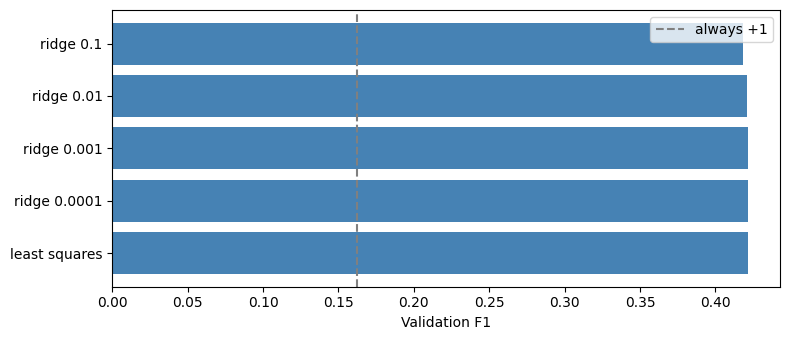

In [ ]:
results = []
results.append(run_cv("least squares", lambda X, y: least_squares(y.astype(float), X)[0], "score"))
for lam in RIDGE_LAMBDAS:
    results.append(
        run_cv(
            f"ridge {lam:g}",
            lambda X, y, lam=lam: ridge_regression(y.astype(float), X, lam)[0],
            "score",
        )
    )

show(results)
means = [f1_mean_std(record)[0] for record in results]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(np.arange(len(results)), means, color="steelblue")
ax.set_yticks(np.arange(len(results)))
ax.set_yticklabels([record["name"] for record in results])
ax.axvline(f1_score(y_train, always_pos), color="gray", ls="--", label="always +1")
ax.set_xlabel("Validation F1")
ax.legend()
fig.tight_layout()
save_figure(fig, "least_squares_ridge_f1.png")
plt.show()


## Does gradient descent actually descend?

One training fold of the basic matrix. If the curve is still dropping at the right edge, raise `GD_ITERS` or `LOG_ITERS`. If it climbs, lower the step size.


mse gd: loss 0.1597 -> 0.1322
logistic: loss 0.2488 -> 0.2198
reg logistic 1e-3: loss 0.2500 -> 0.2207
Wrote C:\Users\stoja\PycharmProjects\CS-433-First-Project\results\figures\training_loss.png


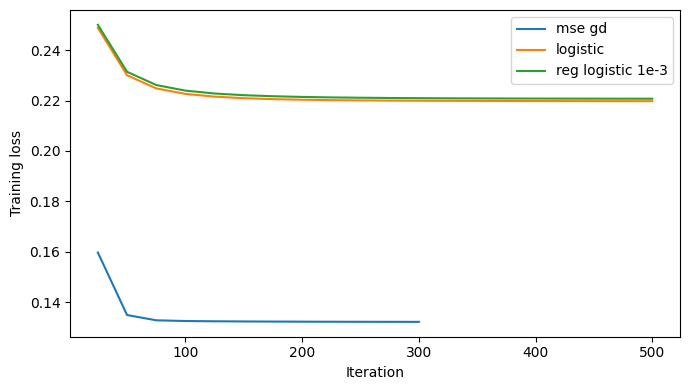

In [ ]:
tr, va = next(stratified_folds(y_train, N_FOLDS, SEED))
prep = base.fold(tr, va)
prep.clean()
prep.add_bias()
Xtr = prep.x_train
del prep
ytr = y_train[tr].astype(float)
y01 = (y_train[tr] == 1).astype(float)


def trace(update, n_iter, chunk=25):
    w = np.zeros(Xtr.shape[1])
    history = []
    done = 0
    while done < n_iter:
        step = min(chunk, n_iter - done)
        with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
            w, loss = update(w, step)
        done += step
        history.append((done, float(loss)))
        if not np.isfinite(loss):
            break
    return history


curves = {
    "mse gd": trace(lambda w, n: mean_squared_error_gd(ytr, Xtr, w, n, GAMMA_MSE), GD_ITERS),
    "logistic": trace(lambda w, n: logistic_regression(y01, Xtr, w, n, GAMMA_LOG), LOG_ITERS),
    "reg logistic 1e-3": trace(
        lambda w, n: reg_logistic_regression(y01, Xtr, 1e-3, w, n, GAMMA_LOG), LOG_ITERS
    ),
}
for name, history in curves.items():
    print(f"{name}: loss {history[0][1]:.4f} -> {history[-1][1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
for name, history in curves.items():
    ax.plot([step for step, _ in history], [loss for _, loss in history], label=name)
ax.set_xlabel("Iteration")
ax.set_ylabel("Training loss")
ax.legend()
fig.tight_layout()
save_figure(fig, "training_loss.png")
plt.show()


## Logistic regression and full-batch gradient descent

Same five folds and the same basic matrix.


In [ ]:
results.append(
    run_cv(
        "mse gd",
        lambda X, y: mean_squared_error_gd(
            y.astype(float), X, np.zeros(X.shape[1]), GD_ITERS, GAMMA_MSE
        )[0],
        "score",
    )
)
results.append(
    run_cv(
        "logistic",
        lambda X, y: logistic_regression(
            (y == 1).astype(float), X, np.zeros(X.shape[1]), LOG_ITERS, GAMMA_LOG
        )[0],
        "prob",
    )
)
for lam in LOG_LAMBDAS:
    results.append(
        run_cv(
            f"reg logistic {lam:g}",
            lambda X, y, lam=lam: reg_logistic_regression(
                (y == 1).astype(float), X, lam, np.zeros(X.shape[1]), LOG_ITERS, GAMMA_LOG
            )[0],
            "prob",
        )
    )

show(results[-2 - len(LOG_LAMBDAS) :])


mse gd
  fold 1: F1 0.420   default 0.098   cutoff -0.591
  fold 2: F1 0.421   default 0.094   cutoff -0.561
  fold 3: F1 0.423   default 0.095   cutoff -0.562
  fold 4: F1 0.424   default 0.091   cutoff -0.593
  fold 5: F1 0.418   default 0.100   cutoff -0.556
logistic
  fold 1: F1 0.433   default 0.238   cutoff 0.200
  fold 2: F1 0.426   default 0.233   cutoff 0.200
  fold 3: F1 0.430   default 0.233   cutoff 0.190
  fold 4: F1 0.435   default 0.233   cutoff 0.210
  fold 5: F1 0.426   default 0.249   cutoff 0.180
reg logistic 0.0001
  fold 1: F1 0.434   default 0.237   cutoff 0.210
  fold 2: F1 0.427   default 0.232   cutoff 0.190
  fold 3: F1 0.430   default 0.232   cutoff 0.200
  fold 4: F1 0.435   default 0.232   cutoff 0.210
  fold 5: F1 0.426   default 0.248   cutoff 0.210
reg logistic 0.001
  fold 1: F1 0.433   default 0.229   cutoff 0.210
  fold 2: F1 0.427   default 0.222   cutoff 0.200
  fold 3: F1 0.430   default 0.224   cutoff 0.210
  fold 4: F1 0.434   default 0.221   cut

## SGD

One training row per update. The printout under the call says how many times each training row is drawn. A short budget is not a fair loss against full-batch gradient descent.


In [ ]:
fold_rows = len(y_train) * (N_FOLDS - 1) / N_FOLDS
print(f"{SGD_ITERS:,} draws with replacement from about {fold_rows:,.0f} rows ({SGD_ITERS / fold_rows:.2f} per row)")
results.append(
    run_cv(
        "sgd",
        lambda X, y: mean_squared_error_sgd(
            y.astype(float), X, np.zeros(X.shape[1]), SGD_ITERS, GAMMA_SGD
        )[0],
        "score",
    )
)
show(results[-1:])


100,000 draws with replacement from about 262,508 rows (0.38 per row)
sgd
  fold 1: non-finite scores
  fold 2: non-finite scores
  fold 3: non-finite scores
  fold 4: non-finite scores
  fold 5: non-finite scores
model                             F1     std    prec  recall     acc
sgd                             nan    nan    nan    nan    nan


## Ablations

Reference: the ridge penalty with the best F1 above, still on the basic cleaning. Each arm changes one decision. `delta` is the mean of the fold-by-fold F1 differences. A change smaller than `std` is not a result.

Class-weighted logistic regression is not one of the six graded functions. Positive and negative rows are reweighted so each class contributes the same total mass. That arm is compared with unweighted logistic regression at the same penalty.

"Clinical products" adds squares of age, BMI and the health-day counts, and pairwise products of the main risk factors (`add_products`), on top of the reference ridge.


In [ ]:
ridge_runs = [
    record
    for record in results
    if record["name"].startswith("ridge") and np.isfinite(f1_mean_std(record)[0])
]
if not ridge_runs:
    raise RuntimeError("Run the least-squares and ridge cell first.")
reference = max(ridge_runs, key=lambda record: f1_mean_std(record)[0])
ref_lambda = float(reference["name"].split()[-1])
print("Reference:", reference["name"], "F1", round(f1_mean_std(reference)[0], 3))

default_folds = []
for fold in reference["folds"]:
    copied = dict(fold)
    copied["f1"] = fold["f1_default"]
    default_folds.append(copied)
ablations = [{"name": "default cutoff", "folds": default_folds}]


def ridge_on(name, **kwargs):
    return run_cv(
        name,
        lambda X, y, lam=ref_lambda: ridge_regression(y.astype(float), X, lam)[0],
        "score",
        **kwargs,
    )


ablations.append(ridge_on("undersample 1:1", undersample_ratio=1))
ablations.append(ridge_on("undersample 1:3", undersample_ratio=3))


def ridge_free_bias(X, y, lam=ref_lambda):
    # Same normal equations as ridge_regression, except the intercept is not penalized.
    y = y.astype(float)
    penalty = np.full(X.shape[1], 2.0 * len(y) * lam)
    penalty[0] = 0.0
    return np.linalg.solve(X.T @ X + np.diag(penalty), X.T @ y)


ablations.append(run_cv("unpenalized intercept", ridge_free_bias, "score"))


def fit_weighted(X, y, lam=1e-3):
    y01 = (y == 1).astype(float)
    n = len(y01)
    n_pos = max(float(np.sum(y01 == 1)), 1.0)
    n_neg = max(float(n - n_pos), 1.0)
    sample_w = np.where(y01 == 1, n / (2 * n_pos), n / (2 * n_neg))
    w = np.zeros(X.shape[1])
    for _ in range(LOG_ITERS):
        pred = sigmoid(X @ w)
        grad = X.T @ (sample_w * (pred - y01)) / n + 2 * lam * w
        w = w - GAMMA_LOG * grad
    return w


unweighted = run_cv(
    "logistic for the weight check",
    lambda X, y: reg_logistic_regression(
        (y == 1).astype(float), X, 1e-3, np.zeros(X.shape[1]), LOG_ITERS, GAMMA_LOG
    )[0],
    "prob",
)
weighted = run_cv("class weighted logistic", fit_weighted, "prob")

print()
print(f"{'change':<24} {'delta':>8} {'std':>8} {'F1':>8}  against")
for record in ablations:
    delta, std = paired_delta(record, reference)
    mean, _ = f1_mean_std(record)
    print(f"{record['name']:<24} {delta:+8.3f} {std:8.3f} {mean:8.3f}  {reference['name']}")
delta, std = paired_delta(weighted, unweighted)
mean, _ = f1_mean_std(weighted)
print(f"{'class weight':<24} {delta:+8.3f} {std:8.3f} {mean:8.3f}  unweighted logistic")


Reference: ridge 0.001 F1 0.422
undersample 1:1
  fold 1: F1 0.431   default 0.373   cutoff 0.367
  fold 2: F1 0.422   default 0.370   cutoff 0.363
  fold 3: F1 0.429   default 0.372   cutoff 0.358
  fold 4: F1 0.429   default 0.371   cutoff 0.409
  fold 5: F1 0.418   default 0.368   cutoff 0.363
undersample 1:3
  fold 1: F1 0.430   default 0.420   cutoff -0.089
  fold 2: F1 0.427   default 0.420   cutoff -0.086
  fold 3: F1 0.426   default 0.424   cutoff -0.092
  fold 4: F1 0.432   default 0.426   cutoff -0.092
  fold 5: F1 0.425   default 0.417   cutoff -0.083
unpenalized intercept
  fold 1: F1 0.421   default 0.103   cutoff -0.558
  fold 2: F1 0.422   default 0.098   cutoff -0.558
  fold 3: F1 0.422   default 0.101   cutoff -0.560
  fold 4: F1 0.424   default 0.098   cutoff -0.561
  fold 5: F1 0.420   default 0.106   cutoff -0.555
logistic for the weight check
  fold 1: F1 0.433   default 0.229   cutoff 0.210
  fold 2: F1 0.427   default 0.222   cutoff 0.200
  fold 3: F1 0.430   def

## Refit and write a submission

The submitted model is the best of the six required models on the cleaning above: drop administrative columns, decode the codebook codes, drop columns that are more than 90% empty or constant, add missing indicators, one-hot the categorical answers, median-fill, and standardize. The cutoff is the average of that model's validation cutoffs. The winning row was chosen on these same folds, so its F1 is a little optimistic.

This cell writes `results/predictions.csv` and a summary of the tables above in `results/results.md`.


In [ ]:
import os

candidates = [
    record
    for record in results
    if np.isfinite(f1_mean_std(record)[0])
]
winner = max(candidates, key=lambda record: f1_mean_std(record)[0])
mean, std = f1_mean_std(winner)
print(f"Refitting {winner['name']}: F1 {mean:.3f} +/- {std:.3f}")

prep = base.copy()
prep.clean()
prep.add_bias()
if winner["undersample_ratio"] is not None:
    prep.undersample(winner["undersample_ratio"], SEED)
Xtr, Xte, ytr, _, _ = prep.get_processed_data()
w = winner["fit"](Xtr, ytr)
scores = project(Xte, w, winner["kind"])
threshold = float(np.mean([fold["threshold"] for fold in winner["folds"]]))
pred = np.where(scores >= threshold, 1, -1).astype(int)
print(f"cutoff {threshold:.3f}, predicted positive rate {np.mean(pred == 1):.2%}, columns {Xtr.shape[1]}")
os.makedirs(ROOT / "results", exist_ok=True)
pred_path = ROOT / "results" / "predictions.csv"
create_csv_submission(test_ids, pred.tolist(), str(pred_path))
print("Wrote", pred_path)

report = [
    "# Results",
    "",
    "Stratified 5-fold means from `02_models_and_ablations.ipynb`. "
    "F1 uses a cutoff chosen on that fold's validation scores. AUROC does not.",
    "",
    (
        f"Training labels: {int(np.sum(y_train == 1)):,} positive of {len(y_train):,} "
        f"({np.mean(y_train == 1):.2%}). "
        f"Always -1: F1 {f1_score(y_train, majority):.3f}, accuracy {accuracy(y_train, majority):.3f}. "
        f"Always +1: F1 {f1_score(y_train, always_pos):.3f}, accuracy {accuracy(y_train, always_pos):.3f}."
    ),
    "",
    "## Models",
    "",
    metric_table(results),
    "",
    "## Ablations",
    "",
    f"Reference: {reference['name']}. `delta` is the mean of the fold-by-fold F1 differences.",
    "",
    "| change | delta | std | F1 | against |",
    "| --- | ---: | ---: | ---: | --- |",
]
for record in ablations:
    delta, spread = paired_delta(record, reference)
    f1, _ = f1_mean_std(record)
    report.append(ablation_row(record["name"], delta, spread, f1, reference["name"]))
delta, spread = paired_delta(weighted, unweighted)
f1, _ = f1_mean_std(weighted)
report.append(ablation_row("class weight", delta, spread, f1, "unweighted logistic"))
report.extend(
    [
        "",
        "## Figures",
        "",
        "Least squares and ridge. The dashed line is always predicting +1.",
        "",
        "![Validation F1 for least squares and ridge](figures/least_squares_ridge_f1.png)",
        "",
        "Training loss on the first fold.",
        "",
        "![Training loss](figures/training_loss.png)",
        "",
    ]
)

n_pos = int(np.sum(pred == 1))
report.extend(
    [
        "",
        "## Predictions",
        "",
        (
            f"Refit `{winner['name']}` on all training rows. "
            f"Validation F1 {fmt(mean)} +/- {fmt(std)}. "
            f"Cutoff {threshold:.3f}. "
            f"Predicted +1 on {n_pos:,} of {len(pred):,} test rows ({n_pos / len(pred):.2%})."
        ),
        "",
        "The submission file is [predictions.csv](predictions.csv), with columns `Id` and `Prediction`.",
        "",
    ]
)
report_path = ROOT / "results" / "results.md"
report_path.write_text("\n".join(report), encoding="utf-8")
print("Wrote", report_path)


Refitting logistic: F1 0.430 +/- 0.004
cutoff 0.196, predicted positive rate 14.05%, columns 589
Wrote C:\Users\stoja\PycharmProjects\CS-433-First-Project\results\predictions.csv
Wrote C:\Users\stoja\PycharmProjects\CS-433-First-Project\results\results.md
